In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from scipy.ndimage import convolve, gaussian_filter


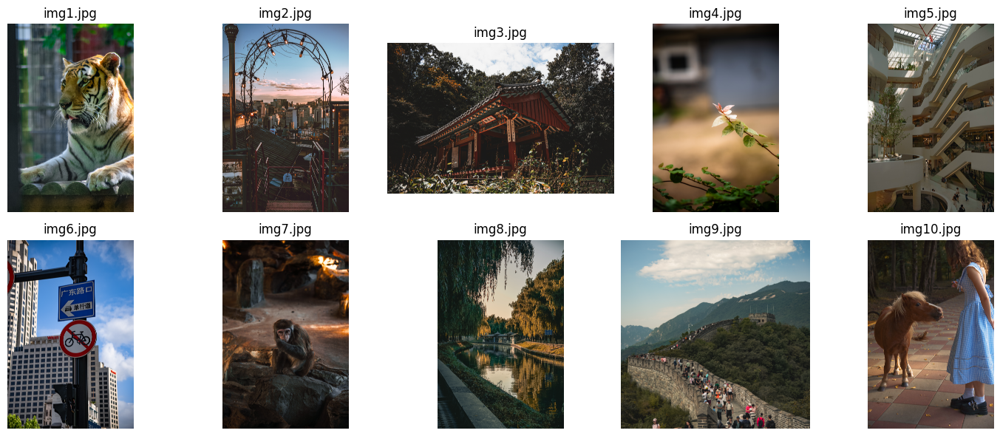

In [13]:

image_paths = [
    os.path.join("img", f"img{i}.jpg")
    for i in range(1, 11)
]

# Plot for reference
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, path in zip(axes.flat, image_paths):
    if os.path.exists(path):
        ax.imshow(Image.open(path))
        ax.set_title(os.path.basename(path))
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:


images = {}

# Load images and turn them into grayscale and normalise
for path in image_paths:
    if os.path.exists(path):
        image = Image.open(path).convert("L")
        images[os.path.basename(path)] = np.array(
            image, dtype=np.float64
        ) / 255.0



In [10]:

# functions needed for the gaussian derivative edge detection


def create_kernel(size, sigma):
   

    radius = size // 2

    coordinates = np.arange(-radius, radius + 1, dtype=float)
    x, y = np.meshgrid(coordinates, coordinates)

    gaussian = np.exp(
        -(x**2 + y**2) / (2 * sigma**2)
    )

    # This math if from the internet
    gaussian /= gaussian.sum()

    
    kernel_x = -(x / sigma**2) * gaussian
    kernel_y = -(y / sigma**2) * gaussian

    
    kernel_x -= kernel_x.mean()
    kernel_y -= kernel_y.mean()

    return kernel_x, kernel_y



def convolveXY(image, size=3, sigma=1.0):


    kernel_x, kernel_y = create_kernel(
        size, sigma
    )

    gradient_x = convolve(image, kernel_x, mode="reflect")
    gradient_y = convolve(image, kernel_y, mode="reflect")

    magnitude = np.sqrt(gradient_x**2 + gradient_y**2)

    return magnitude



    


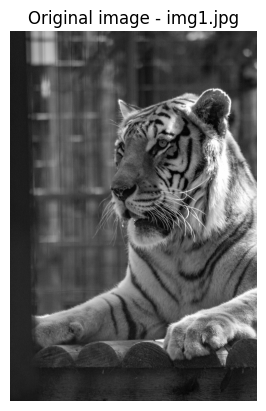

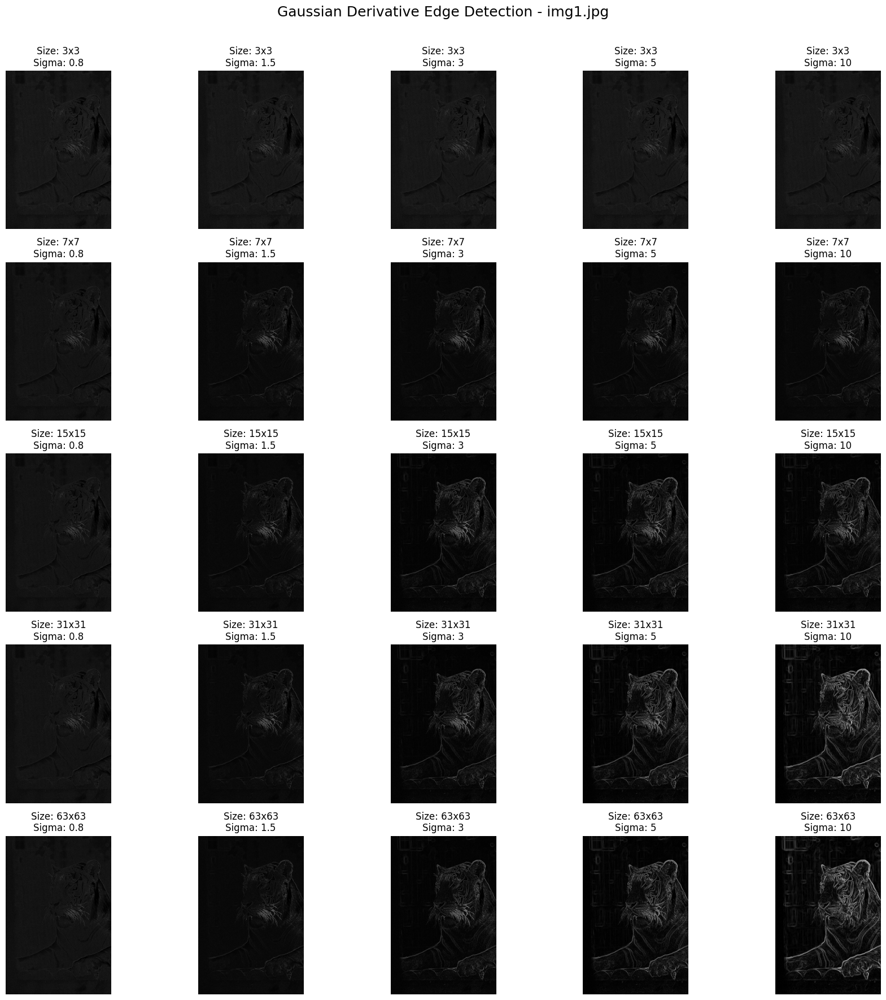

In [4]:

# Experiment A: We first create a matrix of filter sizes and sigma values to understand how they affect eachother.


filter_sizes = [ 3, 7, 15, 31, 63]
sigmas = [0.8, 1.5, 3, 5, 10]

# Select the first image
image_name = next(iter(images))
image = images[image_name]

plt.imshow(image, cmap="gray"); plt.title(f"Original image - {image_name}"); plt.axis("off"); plt.show()

fig, axes = plt.subplots(
    len(filter_sizes),
    len(sigmas),
    figsize=(18, 18)
)

for row, size in enumerate(filter_sizes):
    for col, sigma in enumerate(sigmas):

        ax = axes[row, col]

        convolution = convolveXY(image,size=size,sigma=sigma)
        max_magnitude = convolution.max()
        convolution = convolution / max_magnitude

        ax.imshow(
            convolution,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        ax.set_title(
            f"Size: {size}x{size}\nSigma: {sigma}"
        )
        ax.axis("off")

fig.suptitle(
    f"Gaussian Derivative Edge Detection - {image_name}",
    fontsize=18
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [5]:
#We can see that as the filter size increases, the edges become more pronounced;
# I would assume this is also related to the size of the images

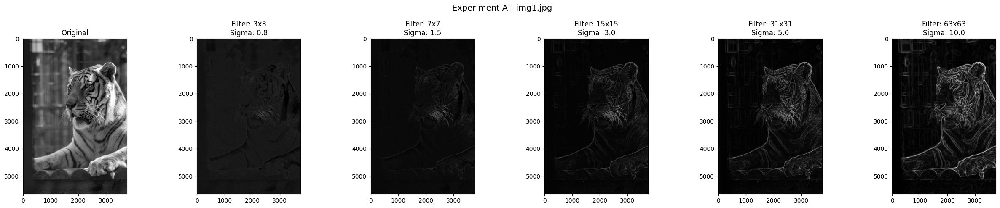

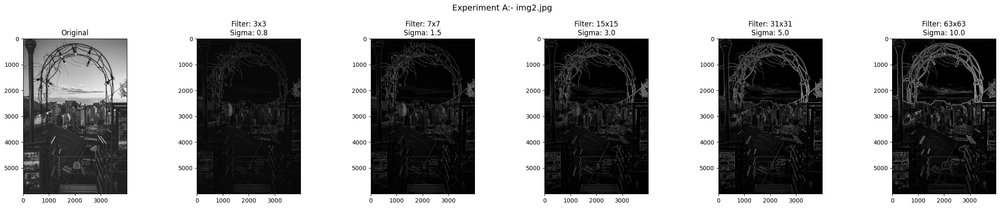

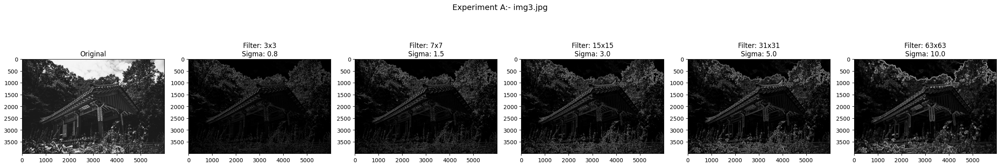

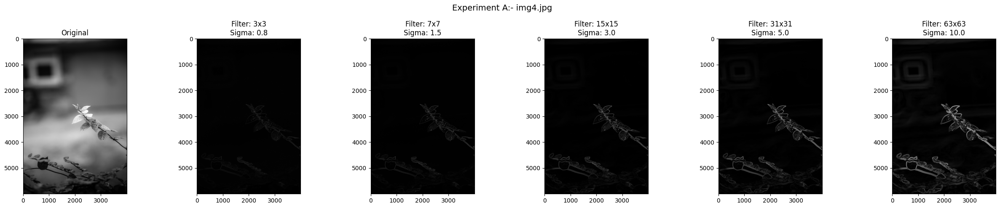

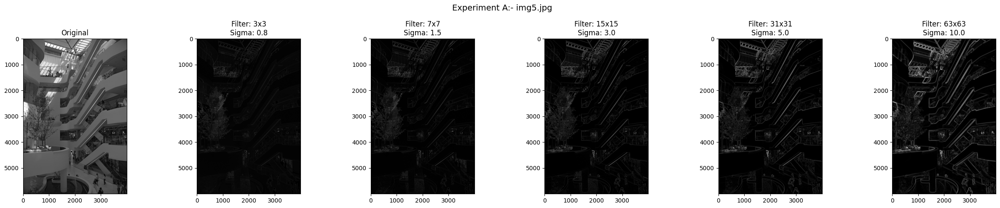

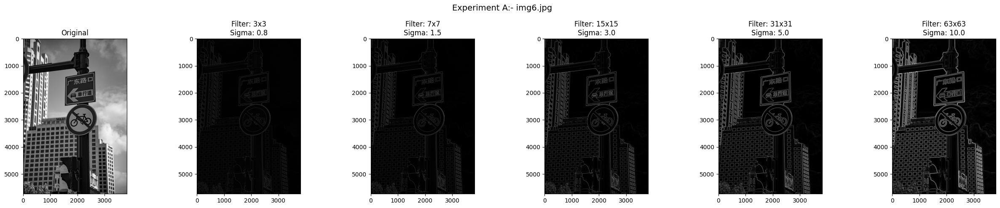

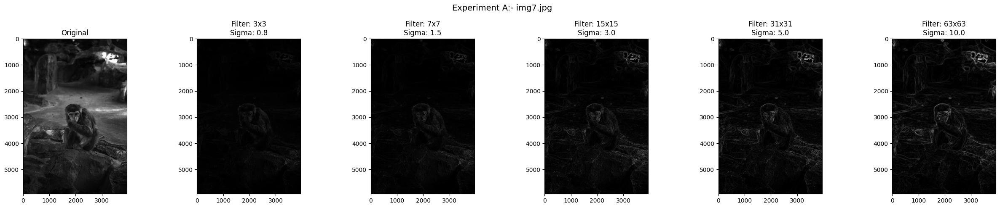

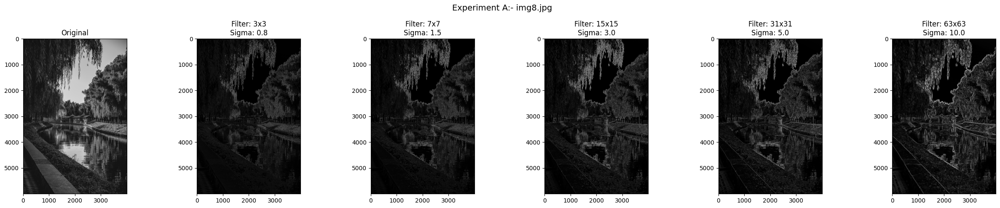

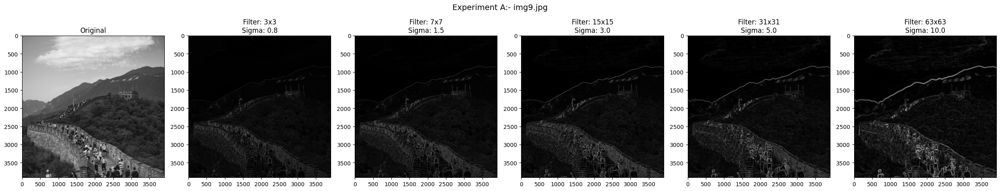

In [ ]:

# repeat process for all images

# i ve decided to use 5 scales instead of 3, as the larger scales seem to be more effective in detecting edges in larger images
scales = [
    (3, 0.8),
    (7, 1.5),
    (15, 3.0),
    (31, 5.0),
    (63, 10.0)

]

for image_name, image in images.items():

    fig, axes = plt.subplots(1, 6, figsize=(25, 5))

    axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Original")

    for index, (size, sigma) in enumerate(scales, start=1):

        
        convolution = convolveXY(image,size=size,sigma=sigma)
        max_magnitude = convolution.max()
        convolution = convolution / max_magnitude

        axes[index].imshow(
            convolution,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[index].set_title(
            f"Filter: {size}x{size}\nSigma: {sigma}"
        )

    

    fig.suptitle(
        f"Experiment A:- {image_name}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


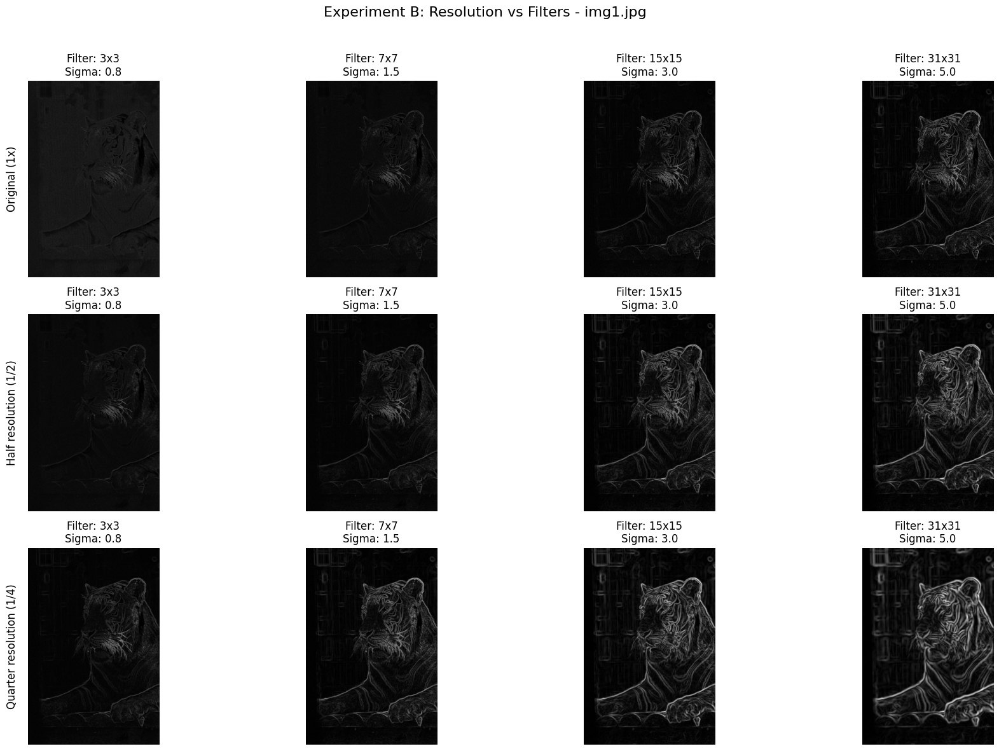

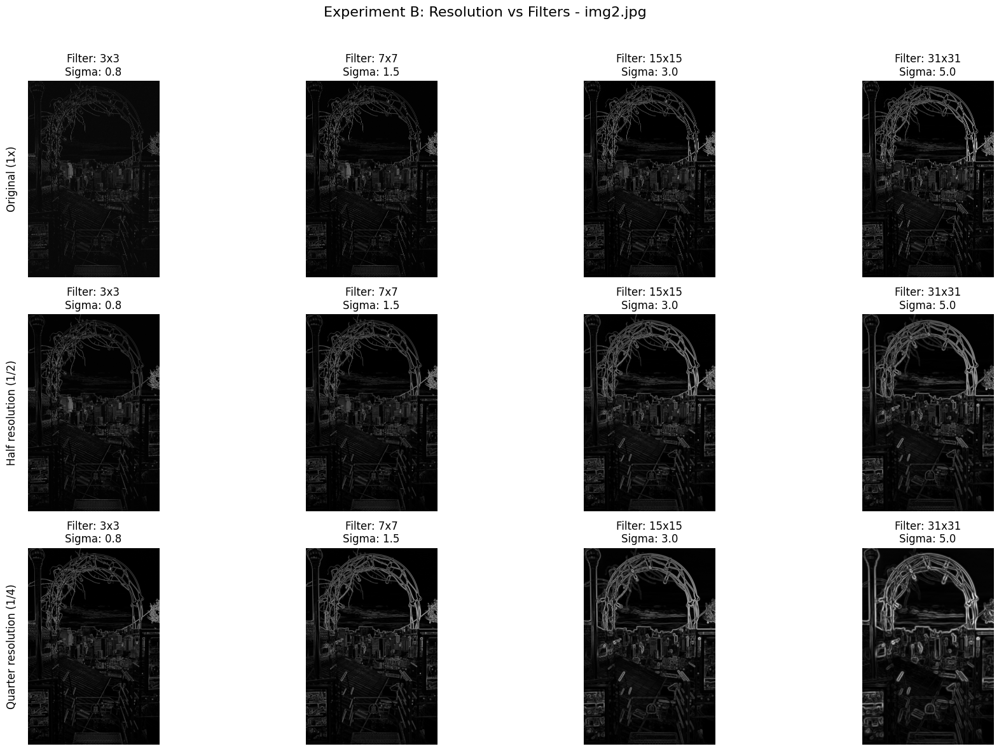

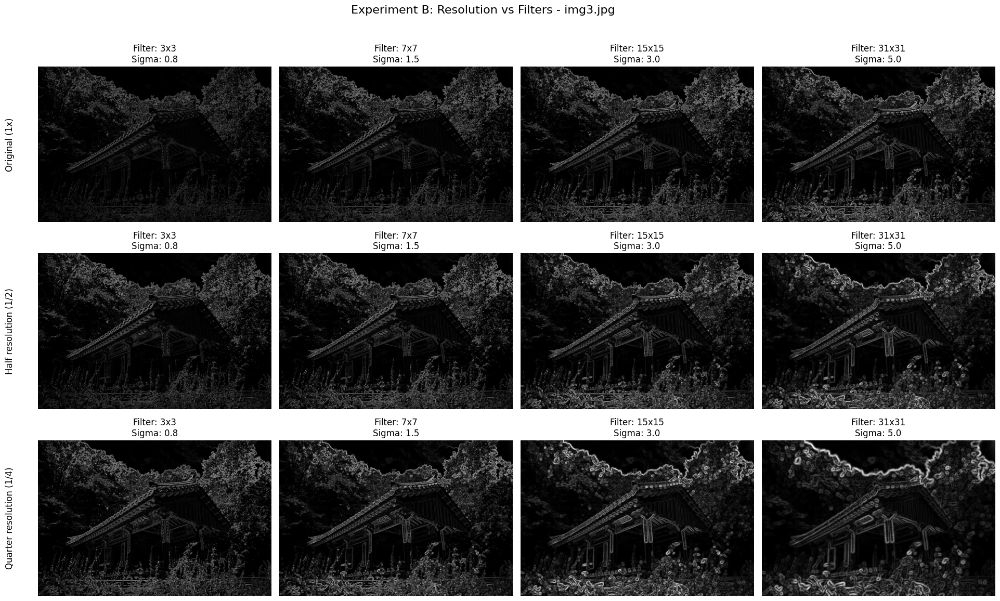

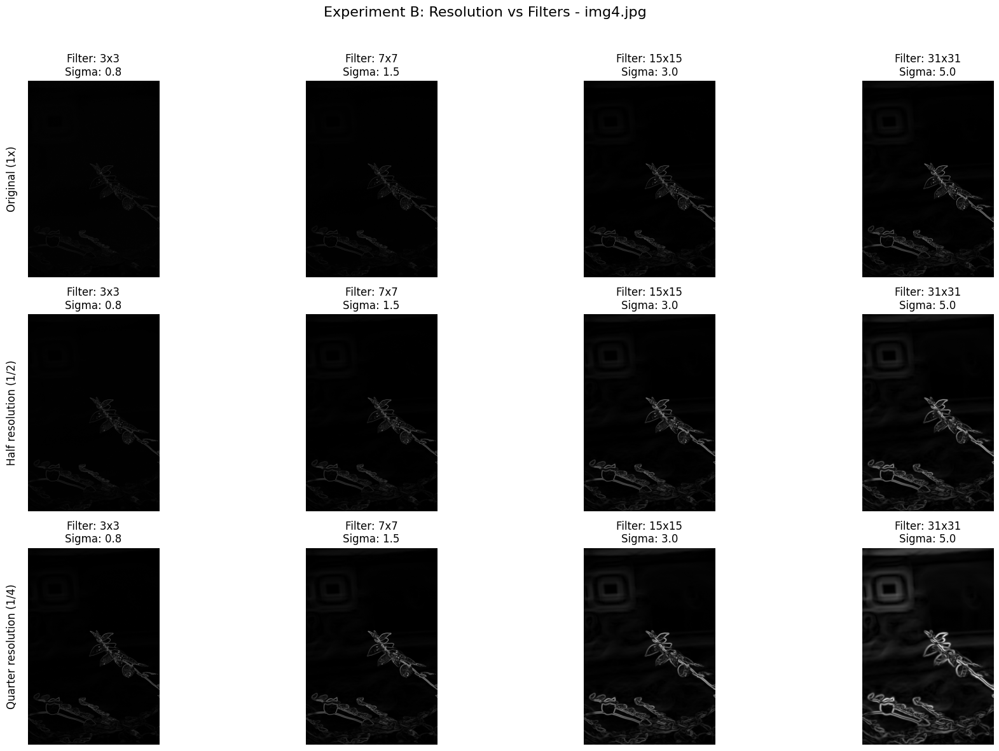

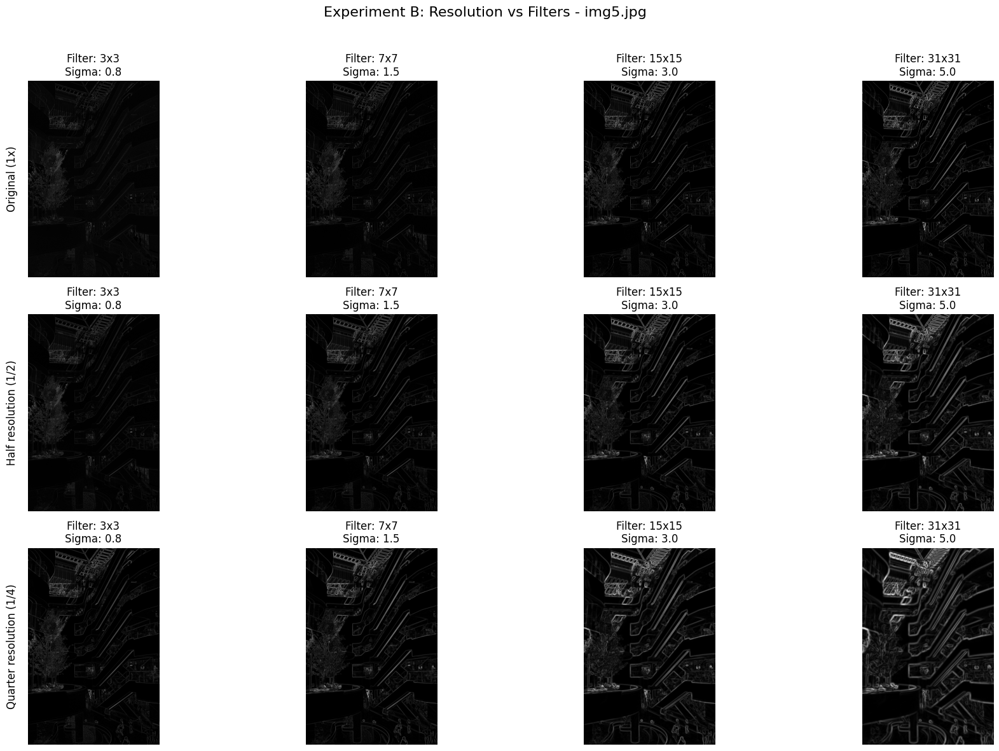

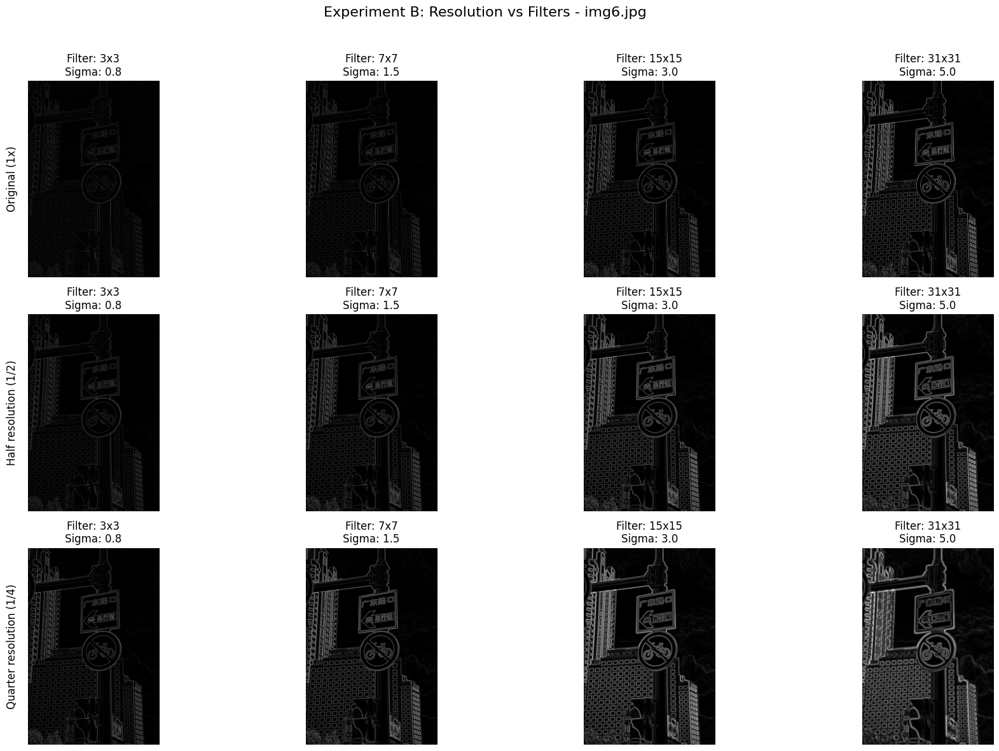

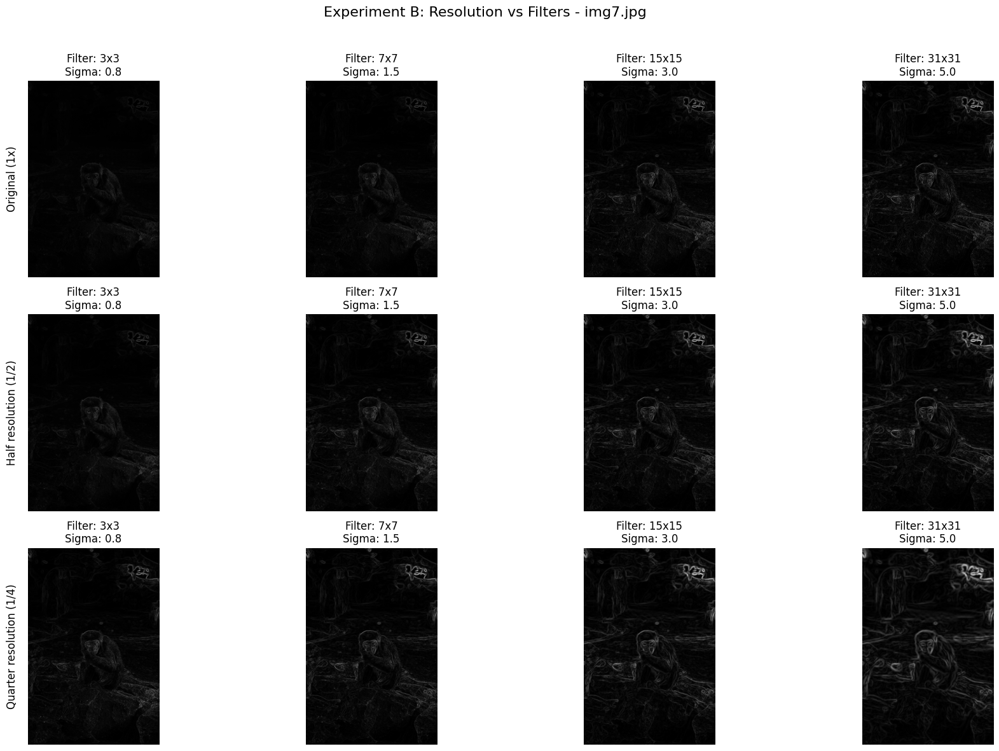

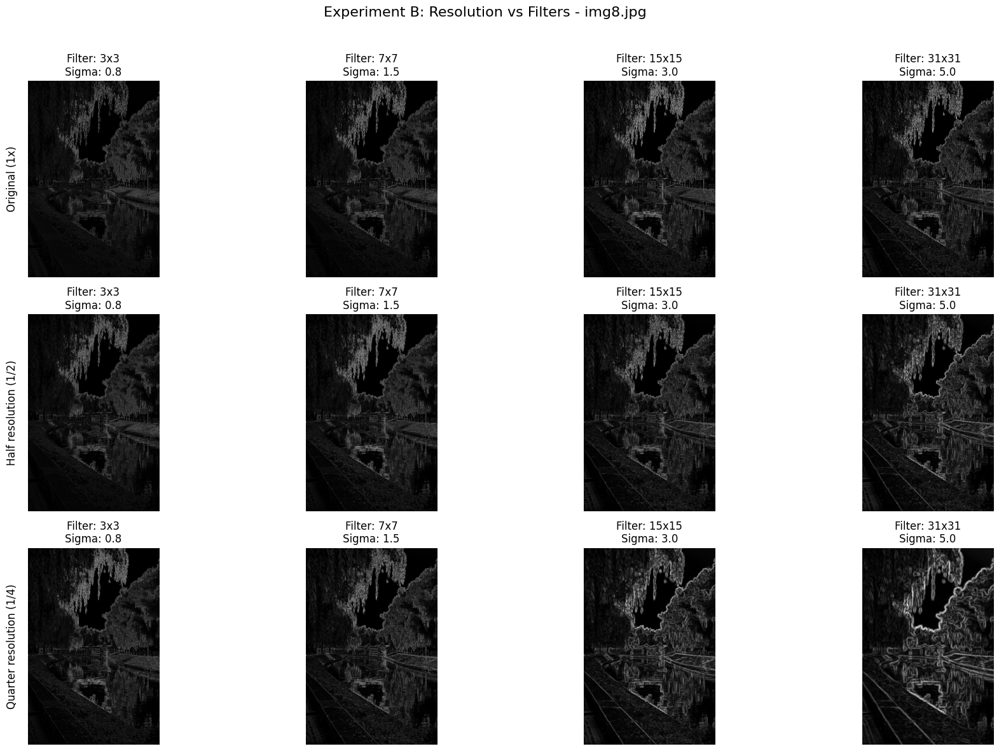

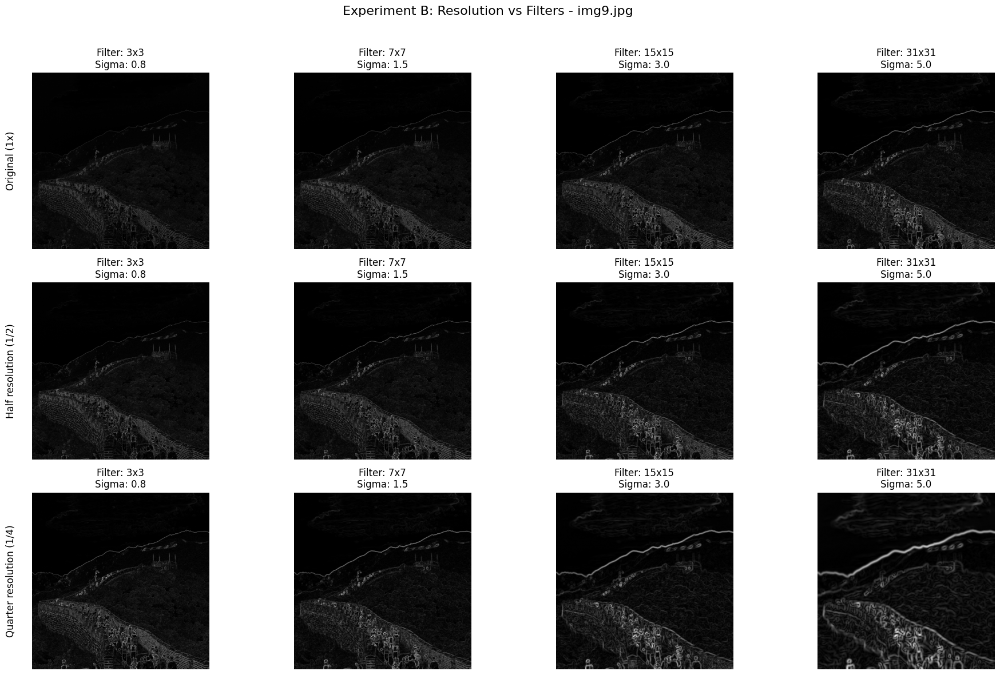

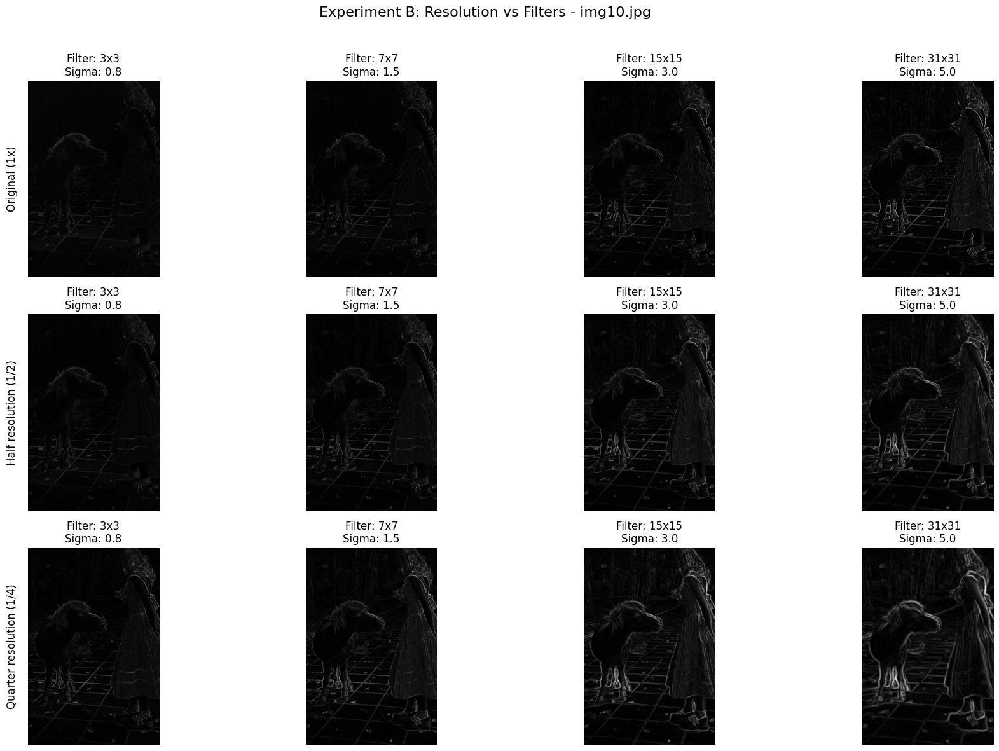

In [12]:


scales = [
    (3, 0.8),
    (7, 1.5),
    (15, 3.0),
    (31, 5.0),
]
# Last scale war removed to preserve computational time

resolutions = [
    (1.0, "Original (1x)"),
    (0.5, "Half resolution (1/2)"),
    (0.25, "Quarter resolution (1/4)")
]


for image_name, image in images.items():

    fig, axes = plt.subplots(
        len(resolutions), len(scales),
        figsize=(5 * len(scales), 4 * len(resolutions))
    )

    for row, (factor, resolution_name) in enumerate(resolutions):

        if factor == 1.0:
            resized = image
        else:
            new_width = max(1, int(image.shape[1] * factor))
            new_height = max(1, int(image.shape[0] * factor))

            resized = np.array(
                Image.fromarray(
                    (image * 255).astype(np.uint8)
                ).resize(
                    (new_width, new_height),
                    Image.Resampling.LANCZOS
                ),
                dtype=np.float64
            ) / 255.0

        for col, (size, sigma) in enumerate(scales):

            convolution = convolveXY(
                resized, size=size, sigma=sigma
            )

            max_magnitude = convolution.max()

            if max_magnitude > 0:
                convolution = convolution / max_magnitude

            axes[row, col].imshow(
                convolution,
                cmap="gray",
                vmin=0,
                vmax=1
            )

            axes[row, col].set_title(
                f"Filter: {size}x{size}\nSigma: {sigma}"
            )
            axes[row, col].axis("off")

        # Add the resolution label at the start of each row
        axes[row, 0].text(
            -0.12, 0.5, resolution_name,
            transform=axes[row, 0].transAxes,
            rotation=90,
            ha="center",
            va="center",
            fontsize=12
            )

    fig.suptitle(
        f"Experiment B: Resolution vs Filters - {image_name}",
        fontsize=16
    )

    plt.tight_layout(rect=[0.04, 0, 1, 0.96])
    plt.show()